In [1]:
import torch
import torch.nn as non
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

print("Pytorch version:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

Pytorch version: 2.15.0+cpu
CUDA disponible: False


1. WORKFLOW général

In [2]:
#Le cycle de  base est:
#Données -> Tensors -> Modèles -> Predictions -> Loss -> Backwards -> Optimizer -> Mise à jour

In [ ]:
# Pseudo-code de la logique generale
# y_pred = model(X)
# loss = criterion(y_pred, y)
# optimizer.zero_grad()
# loss.backward()
# optmizer.step()

2. Les Tensors

Un Tensor est une structure de données fondamentale de pytorch

In [5]:
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

print("scalar: ", scalar, "shape =",scalar.shape)
print("vector: ", vector, "shape =",vector.shape)
print("matrix: ", matrix, "shape =",matrix.shape)
print("dtype:", matrix.dtype)
print("ndim:", matrix.ndim)


scalar:  tensor(3.) shape = torch.Size([])
vector:  tensor([1., 2., 3.]) shape = torch.Size([3])
matrix:  tensor([[1., 2.],
        [3., 4.]]) shape = torch.Size([2, 2])
dtype: torch.float32
ndim: 2


Manipulation de Tensors

In [7]:
x = torch.arange(12)
print("x =",x)

x2 =x.reshape(3,4)
print("reshape(3,4):", x2)

print("Colonne 1", x2[:,1])
print("Ligne 0", x2[0,:])

A = torch.tensor([[1., 2.],[3., 4.]])
B = torch.tensor([[2., 0.],[1., 2.]])
print("A @ B =", A @ B)


x = tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
reshape(3,4): tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
Colonne 1 tensor([1, 5, 9])
Ligne 0 tensor([0, 1, 2, 3])
A @ B = tensor([[ 4.,  4.],
        [10.,  8.]])


3. CPU, GPU et device

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé:", device)

x = torch.tensor([1.0, 2.0, 3.0]).to(device)
print("x.device =", x.device)

Device utilisé: cpu
x.device = cpu


4. Autograd calcul automatiquement les dérivées à partir du graphe de calcul

In [9]:
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w*x + b
loss = (y-10)**2 

loss.backward()
print("y =",y.item())
print("loss =",loss.item)
print("dLoss/dw =", w.grad.item())
print("dLoss/db =", b.grad.item())

y = 7.0
loss = <built-in method item of Tensor object at 0x0000021C5DCA9180>
dLoss/dw = -12.0
dLoss/db = -6.0


In [10]:
import torch

x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w*x + b
loss = (y-10)**2 

dw,db = torch.autograd.grad(loss,(w,b))

print("y =",y.item())
print("loss =",loss.item)
print("dLoss/dw =", dw.item())
print("dLoss/db =", db.item())

y = 7.0
loss = <built-in method item of Tensor object at 0x0000021C5DCAC870>
dLoss/dw = -12.0
dLoss/db = -6.0


In [ ]:
#Base de pyTorch
X = torch.randn(100,3) #j'ai 3 variable feature
y = torch.randn(100, 1) #j'ai une seule sortie

dataset = TensorDataset(X, y)
loader = DataLoader(dataset, batch_size=16, shuffle=True)# pour chaque forward il va prendre 16 exemple
#le batch size est un hyperparametre et souvent on a besoin de le regler
# suffle =True, il va melanger les données

for X_batch, y_batch in loader:
    print("Batch X:", X_batch.shape, "Batch y:", y_batch.shape)
    break

Batch X: torch.Size([16, 3]) Batch y: torch.Size([16, 1])


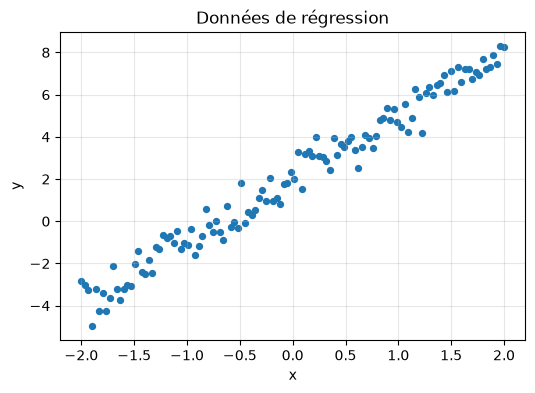

In [ ]:
# Regression ineaire
torch.manual_seed(42)
X = torch.linspace(-2,2,120).unsqueeze(1) # generer un vecteur x entre -2 et 2; 100 valeurs
noise = 0.6 * torch.randn_like(X)
y = 3*X + 2 + noise
plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18)
plt.title("Données de régression")

plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

In [19]:
import torch.nn as nn #tous les classe concernant le reseau de neurone se trouve dans ce package
model_reg = nn.Linear(1,1)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_reg.parameters(), lr=0.05)


In [ ]:
losses = []

for epoch in range(300):
    model_reg.train() # je suis dans le mode train
    y_pred = model_reg(X)
    loss = criterion(y_pred,y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    
print("Dernier loss:", losses[-1])
print("w appris:",model_reg.weight.item())
print("b appris:", model_reg.bias.item())

Dernier loss: 0.3438417613506317
w appris: 2.989469289779663
b appris: 2.0300137996673584


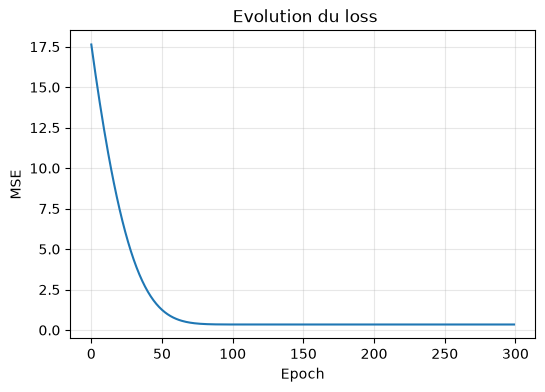

In [21]:
plt.figure(figsize=(6,4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title(" Evolution du loss")
plt.grid(True, alpha=0.3)
plt.show()

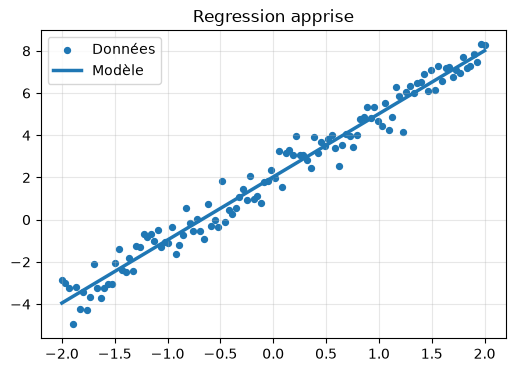

In [ ]:
# evaluation du model, dans la realite il faut utiliser un autre set pour tester
model_reg.eval() 

with torch.inference_mode():
    y_hat = model_reg(X)
plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18, label="Données")
plt.plot(X.numpy(),y_hat.numpy(),linewidth=2.5, label= "Modèle")
plt.legend()
plt.title("Regression apprise")
plt.grid(True,alpha=0.3)
plt.show()

In [23]:
from torcheval.metrics import R2Score
metric = R2Score()
metric.update(y_hat,y)
r2=metric.compute()
print(f"R2 Score = {r2:.3f}") 

R2 Score = 0.972


In [24]:
# Exemple de classification

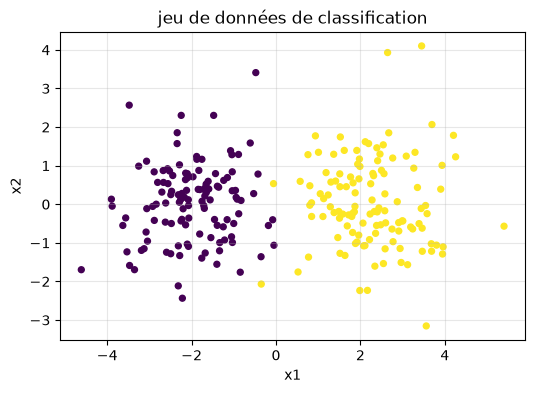

In [ ]:
#creation de deux classes de point en 2D

torch.manual_seed(0)
n=120
# je vais generer 120 couples;
class0 = torch.randn(n,2) + torch.tensor([-2.0, 0.0])
class1 = torch.randn(n,2) + torch.tensor([2.0, 0.0])

X_cls = torch.cat([class0, class1], dim=0) #je veux empiler les deux tenseurs
y_cls = torch.cat( [
    torch.zeros(n, dtype=torch.long),
    torch.ones(n,dtype=torch.long)
])

plt.figure(figsize=(6,4))
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("jeu de données de classification")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True, alpha=0.3)
plt.show()

In [31]:
# classification model
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16,16),
            nn.ReLU(),
            nn.Linear(16,2)       
        )
    
    def forward(self, x):
        return self.net(x)

In [32]:
model_cls = Classifier()
criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = torch.optim.Adam(model_cls.parameters(), lr=0.1)

In [33]:
losses_cls = []
for epoch in range(250):
    model_cls.train()
    logits = model_cls(X_cls)
    loss = criterion_cls(logits,y_cls)
    optimizer_cls.zero_grad()
    loss.backward()
    optimizer_cls.step()
    losses_cls.append(loss.item())
    
print("Dernier loss:", losses_cls[-1])

Dernier loss: 4.66901290963051e-08


In [34]:
model_cls.eval()
with torch.inference_mode():
    logits = model_cls(X_cls)
    pred = logits.argmax(dim=1)
    accuracy = (pred == y_cls).float().mean()
print(f"Accuracy = {accuracy.item()*100:.2f}%")

Accuracy = 100.00%


In [35]:
# Google Brain a crée tensorflow: Matin Abadi, Jeff Dean, Rajat Monga
# Facebook AI Research(FAIR) a crée pytorch: Adam Paszke, Sam Gross, Soumith Chintala et Gregory Chanan

In [39]:
import torch
import torch.nn as nn
from torchviz import make_dot

model = nn.Linear(3,1)# un model lineaire à 3 entrée et une sortie
x = torch.tensor([[1.0, 2.0, 3.0]])
y =model(x) # je vais un forward <=> je fais un predict vs model.predict(x)

print("Sortie:", y)
print("Poids:", model.weight)
print("Biais", model.bias)
dot = make_dot(y, params=dict(model.named_parameters()))

Sortie: tensor([[1.0900]], grad_fn=<AddmmBackward0>)
Poids: Parameter containing:
tensor([[0.0498, 0.4507, 0.1082]], requires_grad=True)
Biais Parameter containing:
tensor([-0.1857], requires_grad=True)


In [41]:
#dot.render("graphe_operations", format="png", cleanup=True)

In [ ]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__() #faire appel au constructeur de la classe parente
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8,3)
        )
    def forward(self,x):  #redefinir la methode forward
        return self.net(x)

model = MLP()
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


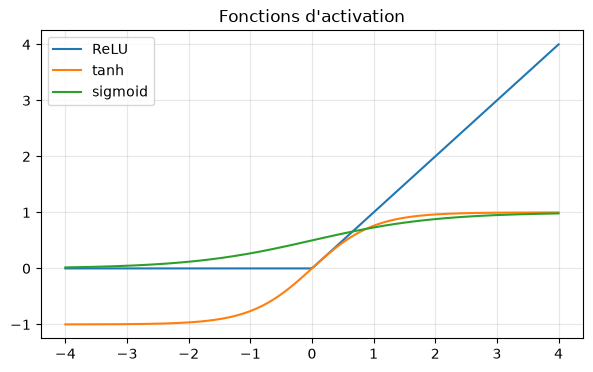

In [ ]:
# les functions d'activations
x = torch.linspace(-4, 4, 200) #genere 200 valeurs comprise entre -4 et 4
relu = torch.relu(x)
tanh = torch.tanh(x)
sigmoid = torch.sigmoid(x)

plt.figure(figsize=(7,4))
plt.plot(x.numpy(),relu.numpy(),label='ReLU')
plt.plot(x.numpy(),tanh.numpy(),label='tanh')
plt.plot(x.numpy(),sigmoid.numpy(),label='sigmoid')
plt.grid(True, alpha = 0.3)
plt.legend()
plt.title("Fonctions d'activation")
plt.show()



In [45]:
# loss function; function cout

# régression
criterion_reg = nn.MSELoss()
y_pred = torch.tensor([[2.0],[4.0]])
y_true = torch.tensor([[3.0],[5.0]])
print("MSE=", criterion_reg(y_pred,y_true).item())

# Classification multi-classe
criterion_cls = nn.CrossEntropyLoss()
pred = torch.tensor([[2.0,1.0,0.5],[0.2,0.1,2.0]])
y = torch.tensor([0,2])
print("CrossEntropy =", criterion_cls(pred, y).item())

MSE= 1.0
CrossEntropy = 0.36905235052108765


In [46]:
# L'optimiseur utilise les graidents pour mettre à jour les paramètres
simple_model =nn.Linear(1,1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


In [ ]:

X = torch.randn(8, 1)
y = 2 * X + 1
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(
    simple_model.parameters(),
    lr=1e-2
)

criterion = nn.MSELoss()

# Boucle d'apprentissage
for epoch in range(500):
    simple_model.train()
    y_pred = simple_model(X)
    loss = criterion(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 100 ==0:
        print(f"epoch={epoch} loss={loss.item():.4f}")

In [48]:
# train() vs eval()
class DropoutDemo(nn.Module):
    def __init__(self):
        super().__init__()
        self.dropout = nn.Dropout(p=0.5)
        
    def forward(self, x):
        return self.dropout(x)

m = DropoutDemo()
x = torch.ones(10)

m.train()
print("train() :",m(x))

m.eval()
with torch.inference_mode():
    print("eval() :",m(x))


train() : tensor([0., 0., 2., 2., 2., 2., 0., 2., 0., 2.])
eval() : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])
